# **Brazilian E-Commerce Customers Analysis**

# Objective
Melakukan segmentasi pelanggan berbasis metode RFM (Recency, Frequency, Monetary) untuk mengidentifikasi karakteristik pelanggan bernilai tinggi (high-value customers) serta memahami pola kontribusi belanja mereka terhadap total pendapatan perusahaan.

In [ ]:
from google.colab import auth
from google.cloud import bigquery
import pandas as pd

# 1. Otentikasi Google Account
auth.authenticate_user()

# 2. Set Project ID & Region Dataset
PROJECT_ID = 'brazilian-e-commerce-public'
LOCATION = 'asia-southeast1'

# 3. Inisialisasi BigQuery Client dengan Location
client = bigquery.Client(project=PROJECT_ID, location=LOCATION)

# 4. Query SQL
sql_query = """
SELECT
  c.customer_unique_id,
  o.order_id,
  o.order_purchase_timestamp,
  c.customer_state,
  SUM(i.price) AS total_order_value,
  SUM(i.price + i.freight_value) AS total_order_value_with_freight
FROM e_commerce_public.orders o
JOIN e_commerce_public.customers c ON o.customer_id = c.customer_id
JOIN e_commerce_public.order_items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY 1, 2, 3, 4;
"""

# 5. Tarik data ke Pandas DataFrame
print("Mengambil data dari BigQuery...")
df = client.query(sql_query).to_dataframe()

# Convert timestamp ke format datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

print(f"Selesai! Total rows berhasil ditarik: {len(df):,}")
df.head()

Mengambil data dari BigQuery...
Selesai! Total rows berhasil ditarik: 96,478


,customer_unique_id,order_id,order_purchase_timestamp,customer_state,total_order_value,total_order_value_with_freight
0,958df1746c3131f9c7359ae5fb848497,7254ba1421bac35de5d5da660715bf0e,2016-10-07 22:46:51+00:00,SE,161.55,176.85
1,6e4c8eed6842146f77d917f7b437b4c2,80606b26965c5ed21e85a085e0667b63,2016-10-04 11:03:14+00:00,RN,148.00,178.11
2,d748ffd406ceef24252c8879c1b27f96,4421f094ff828b78aba6d18db005821d,2016-10-10 10:22:55+00:00,SE,65.90,89.08
3,c6b482cd350f5dc9a48ec4c1292c72bd,5fe46d14177744ae2180101ce19bb414,2016-10-07 10:06:58+00:00,RN,18.90,41.18
4,9342b18c97a2bbf3fa9d97aceb0b6dd4,10d1e90a86d2be981a52b6a927c97dc5,2016-10-06 15:19:40+00:00,RN,399.80,467.20


In [ ]:
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96478 entries, 0 to 96477
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype              
---  ------                          --------------  -----              
 0   customer_unique_id              96478 non-null  object             
 1   order_id                        96478 non-null  object             
 2   order_purchase_timestamp        96478 non-null  datetime64[us, UTC]
 3   customer_state                  96478 non-null  object             
 4   total_order_value               96478 non-null  float64            
 5   total_order_value_with_freight  96478 non-null  float64            
dtypes: datetime64[us, UTC](1), float64(2), object(3)
memory usage: 4.4+ MB


# Cohort Analysis

/tmp/ipykernel_1392/2017010568.py:5: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['order_month'] = df['order_purchase_timestamp'].dt.to_period('M')
/tmp/ipykernel_1392/2017010568.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['cohort_month'] = df.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')


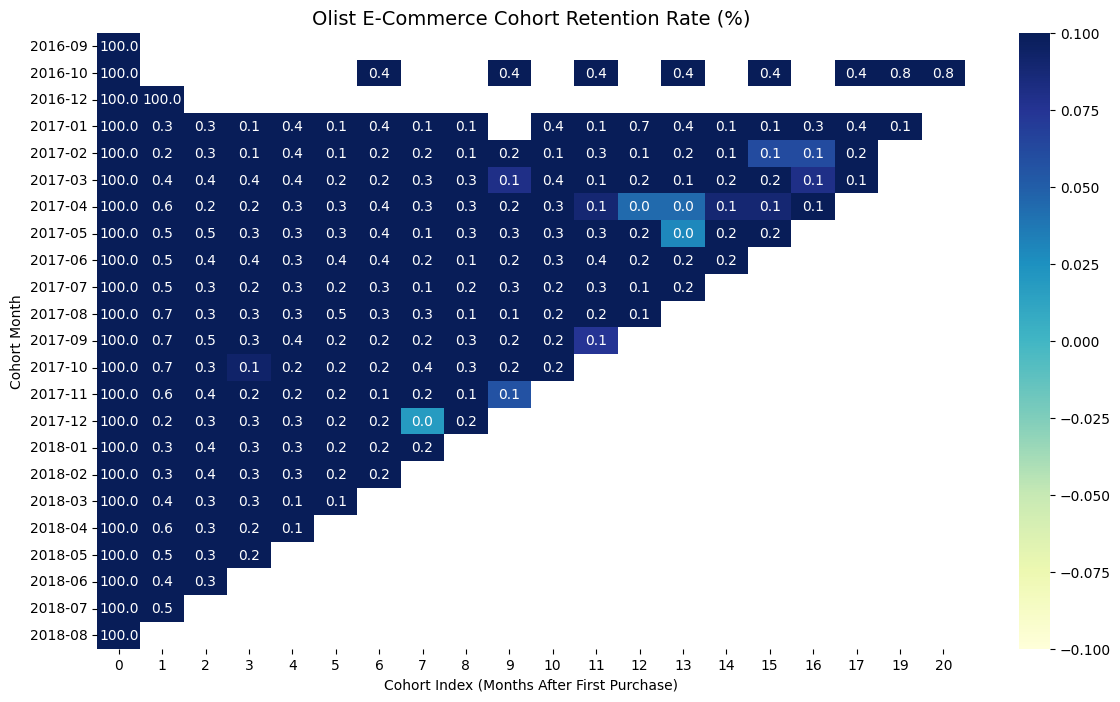

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df['order_month'] = df['order_purchase_timestamp'].dt.to_period('M')
df['cohort_month'] = df.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')

def get_month_offset(df, col1, col2):
  year_diff = df[col1].dt.year - df[col2].dt.year
  month_diff = df[col1].dt.month - df[col2].dt.month
  return year_diff * 12 + month_diff

df['cohort_index'] = get_month_offset(df, 'order_month', 'cohort_month')

# Matrix Cohort
cohort_data = df.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()
cohort_matrix = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

# Retention Rate (%)
cohort_sizes = cohort_matrix.iloc[:, 0]
retention_matrix = cohort_matrix.divide(cohort_sizes, axis=0) * 100

# Plot Heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(retention_matrix, annot=True, fmt='.1f', cmap='YlGnBu', vmin=0, vmax=0)
plt.title('Olist E-Commerce Cohort Retention Rate (%)', fontsize=14)
plt.xlabel('Cohort Index (Months After First Purchase)')
plt.ylabel('Cohort Month')
plt.show()

# RFM Analysis & Customer Segmentation

In [ ]:
max_date = df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm = df.groupby('customer_unique_id').agg({
    'order_purchase_timestamp' : lambda x: (max_date - x.max()).days,
    'order_id' : 'count',
    'total_order_value' : 'sum'
}).reset_index()

rfm.columns = ['customer_unique_id', 'recency', 'frequency', 'monetary']

rfm['R_score'] = pd.qcut(rfm['recency'], q=4, labels=[4, 3, 2, 1])
rfm['M_score'] = pd.qcut(rfm['monetary'], q=4, labels=[1, 2, 3, 4])
rfm['F_score'] = rfm['frequency'].apply(lambda x:1 if x == 1 else (2 if x == 2 else 3))

def segmentation_customer(df):
  if df['R_score'] == 4 and df['F_score'] >= 2:
    return 'Champions'
  elif df['R_score'] >= 3 and df['F_score'] >= 3:
    return 'High Spenders'
  elif df['R_score'] >= 3 and df['F_score'] == 1:
    return 'New Customers'
  elif df['R_score'] == 2:
    return 'Need Attention'
  else :
    return 'Lost'

rfm['customer_segment'] = rfm.apply(segmentation_customer, axis=1)

rfm_summary = rfm.groupby('customer_segment').agg({
    'customer_unique_id' : 'count',
    'recency' : 'mean',
    'frequency' : 'mean',
    'monetary' : ['mean', 'sum']
}).reset_index()

print(rfm_summary)

  customer_segment customer_unique_id     recency frequency    monetary  \
                                count        mean      mean        mean   
0        Champions                783   58.443167  2.155811  277.519310   
1    High Spenders                 66  160.212121  3.484848  368.857879   
2             Lost              24011  443.272708  1.055266  144.535507   
3   Need Attention              23200  277.371810  1.031207  140.163557   
4    New Customers              45298  112.123847  1.000000  138.143390   

               
          sum  
0   217297.62  
1    24344.62  
2  3470442.05  
3  3251794.53  
4  6257619.29  


In [ ]:
# Merge segmen RFM ke transaksi utama
df_final = df.merge(rfm[['customer_unique_id', 'customer_segment', 'recency', 'frequency', 'monetary']], on='customer_unique_id', how='left')

df_final.to_csv('olist_customers_processed_data.csv', index=False)
print("Data berhasil disimpan ke 'olist_processed_data.csv'!")

Data berhasil disimpan ke 'olist_processed_data.csv'!


# Write file app.py

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import plotly.express as px

# --- PAGE CONFIGURATION ---
st.set_page_config(
    page_title="Brazilian E-Commerce Analytics Dashboard",
    page_icon="📊",
    layout="wide"
)

# --- LOAD DATA ---
@st.cache_data
def load_data():
    df = pd.read_csv('olist_processed_data.csv')
    df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
    df['order_month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)
    df['cohort_month'] = pd.to_datetime(df['order_purchase_timestamp']).groupby(df['customer_unique_id']).transform('min').dt.to_period('M').astype(str)
    return df

df_raw = load_data()

# --- SIDEBAR FILTERS ---
st.sidebar.title("Filter Data")
state_list = ['All'] + sorted(df_raw['customer_state'].unique().tolist())
selected_state = st.sidebar.selectbox("Pilih State/Provinsi:", state_list)

if selected_state != 'All':
    df = df_raw[df_raw['customer_state'] == selected_state]
else:
    df = df_raw.copy()

# --- HEADER & KPI SUMMARY ---
st.title("Brazilian E-Commerce Customer Analytics")
st.markdown("End-to-End Portfolio Project: **Cohort Retention, RFM Segmentation & LTV Analysis**")

col1, col2, col3, col4 = st.columns(4)
col1.metric("Total Customers", f"{df['customer_unique_id'].nunique():,}")
col2.metric("Total Orders", f"{df['order_id'].nunique():,}")
col3.metric("Total Revenue", f"R$ {df['total_order_value'].sum():,.2f}")
col4.metric("Avg Order Value (AOV)", f"R$ {df['total_order_value'].mean():,.2f}")

st.divider()

# --- TABS ANALYSIS ---
tab1, tab2, tab3 = st.tabs(["🗓 Cohort Analysis", "RFM Segmentation", "Customer LTV & Insights"])

# TAB 1: COHORT ANALYSIS
with tab1:
    st.subheader("Monthly Cohort Retention Rate (%)")
    df_cohort = df.copy()
    df_cohort['cohort_m'] = pd.to_datetime(df_cohort['cohort_month'])
    df_cohort['order_m'] = pd.to_datetime(df_cohort['order_month'])

    df_cohort['cohort_index'] = (df_cohort['order_m'].dt.year - df_cohort['cohort_m'].dt.year) * 12 + \
                                (df_cohort['order_m'].dt.month - df_cohort['cohort_m'].dt.month)

    cohort_data = df_cohort.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()
    cohort_matrix = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

    cohort_size = cohort_matrix.iloc[:, 0]
    retention_matrix = cohort_matrix.divide(cohort_size, axis=0) * 100

    fig_cohort = px.imshow(
        retention_matrix,
        labels=dict(x="Bulan Ke- (Cohort Index)", y="Cohort Month", color="Retention Rate (%)"),
        x=retention_matrix.columns,
        y=retention_matrix.index,
        color_continuous_scale="Blues",
        aspect="auto",
        text_auto=".1f"
    )
    fig_cohort.update_layout(height=500)
    st.plotly_chart(fig_cohort, use_container_width=True)
    st.info("💡 **Key Insight:** Sebagian besar cohort menunjukkan retention rate < 1% di bulan berikutnya (*one-time buyers*).")

# TAB 2: RFM SEGMENTATION
with tab2:
    st.subheader("Customer Segmentation Based on RFM Model")
    col_rfm1, col_rfm2 = st.columns([1, 1])

    with col_rfm1:
        segment_counts = df.groupby('customer_segment')['customer_unique_id'].nunique().reset_index()
        fig_seg = px.pie(
            segment_counts,
            names='customer_segment',
            values='customer_unique_id',
            title='Distribusi Segmen Pelanggan',
            hole=0.4,
            color_discrete_sequence=px.colors.qualitative.Pastel
        )
        st.plotly_chart(fig_seg, use_container_width=True)

    with col_rfm2:
        st.write("### Profile Metric per Segmen")
        rfm_table = df.groupby('customer_segment').agg(
            Total_Customers=('customer_unique_id', 'nunique'),
            Avg_Recency=('recency', 'mean'),
            Avg_Frequency=('frequency', 'mean'),
            Total_Revenue=('monetary', 'sum')
        ).reset_index()
        st.dataframe(rfm_table.style.format({
            'Total_Customers': '{:,}',
            'Avg_Recency': '{:.1f} hari',
            'Avg_Frequency': '{:.2f}x',
            'Total_Revenue': 'R$ {:,.2f}'
        }), use_container_width=True)

# TAB 3: CUSTOMER LTV & RECOMMENDATIONS
with tab3:
    st.subheader("Customer Lifetime Value (LTV) Breakdown")
    ltv_df = df.groupby('customer_segment').agg(Avg_LTV=('monetary', 'mean')).reset_index()
    fig_ltv = px.bar(
        ltv_df,
        x='customer_segment',
        y='Avg_LTV',
        color='customer_segment',
        title='Rata-Rata Revenue per Pelanggan (Historical LTV)',
        labels={'Avg_LTV': 'Avg LTV (R$)', 'customer_segment': 'Segmen Pelanggan'},
        text_auto='.2f'
    )
    st.plotly_chart(fig_ltv, use_container_width=True)

    st.subheader("Rekomendasi Strategis Bisnis")
    st.markdown("""
    1. **Champions & Loyal Spenders:** Berikan program loyalitas eksklusif (misal: *free shipping threshold*).
    2. **At Risk / Need Attention:** Jalankan strategi *win-back campaign* berupa kupon diskon bertarget.
    3. **New Customers:** Kirimkan *welcome email series* dalam 30 hari pertama untuk menggenjot *activation*.
    """)

Writing app.py


In [ ]:
from google.colab import files

# Download file app.py dan data csv yang sudah diolah
files.download('app.py')
files.download('olist_customers_processed_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>